# AI Road Infrastructure Inspector
## 01 - Data Preparation

Prepare the road damage dataset for YOLOv8 training:
- Explore images and annotations.
- Analyse class distribution.
- Verify bounding boxes.
- Create training, validation and test splits.

Import Libraries

In [1]:
from pathlib import Path
from zipfile import ZipFile
from collections import Counter
import shutil

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from sklearn.model_selection import train_test_split

In [2]:
zip_path = '/content/drive/MyDrive/UK-Road-Damage-Detection/road_damage.zip'

Extract Dataset

In [3]:
with ZipFile(zip_path, 'r') as file:
  file.extractall('/content/road_damage')

Explore Dataset

In [4]:
images = sorted(Path('/content/road_damage').rglob('*.jpeg'))
labels = sorted(path for path in Path('/content/road_damage').rglob('*.txt') if path.name != 'classes.txt')

In [5]:
print(len(images))
print(len(labels))

3321
3321


In [6]:
print('Images without annotation:', sum(not image.with_suffix('.txt').is_file() for image in images))
print('Annotations without image:', len({label.stem for label in labels} - {image.stem for image in images}))

Images without annotation: 0
Annotations without image: 0


Class Distribution

In [7]:
class_counts = Counter()

In [8]:
for label in labels:
  with open(label) as file:
    for line in file:
      if line.strip():
        class_counts[int(line.split()[0])] += 1

In [9]:
for class_id, class_name in enumerate([
    "Pothole",
    "Alligator Crack",
    "Lateral Crack",
    "Longitudinal Crack"
]):
    print(f"{class_id} — {class_name}: {class_counts[class_id]}")

0 — Pothole: 2657
1 — Alligator Crack: 964
2 — Lateral Crack: 1222
3 — Longitudinal Crack: 2156


In [10]:
class_names = [
    "Pothole",
    "Alligator Crack",
    "Lateral Crack",
    "Longitudinal Crack"
]

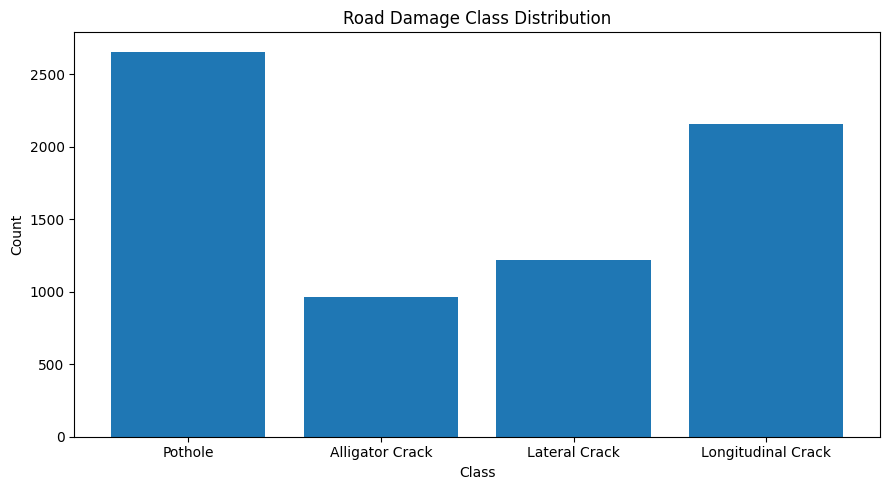

In [11]:
plt.figure(figsize=(9,5))
plt.bar(class_names, [class_counts[i] for i in range(4)])
plt.title('Road Damage Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

Dataset Notes

- The dataset contains 3,321 images and 3,321 annotation files.
- No images without annotations or annotations without images were found.
- There are 6,999 annotated objects across four classes.
- Pothole is the most frequent class, with 2,657 annotations.
- Alligator Crack is the least frequent class, with 964 annotations.

In [12]:
image = Image.open(images[20])
width, height = image.size

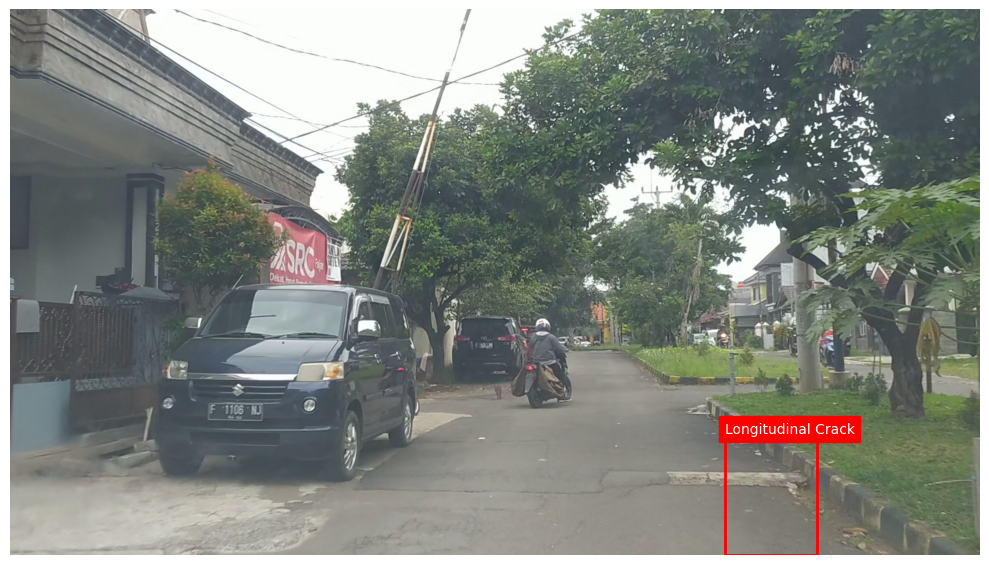

In [15]:
fig, ax = plt.subplots(figsize=(10,7))
ax.imshow(image)

with open(images[20].with_suffix('.txt')) as file:
  for line in file:
    if not line.strip():
      continue

    class_id, x, y, w, h = map(float, line.split())

    x = (x - w / 2) * width
    y = (y - h / 2) * height
    w *= width
    h *= height

    ax.add_patch(
        patches.Rectangle(
            (x,y), w, h, linewidth=2,
            edgecolor='red', facecolor='none')
    )
    ax.text(
        x, y, class_names[int(class_id)],
        color='white', fontsize=10, backgroundcolor='red'
    )

    ax.axis('off')
    plt.tight_layout()
    plt.show()

Split Dataset

Divide the images into training, validation and test sets:

- Training: 70%.
- Validation: 15%.
- Test: 15%.

Use random_state=42 to make the split reproducible.

In [16]:
train_images, temp_images = train_test_split(images, test_size=0.3, random_state=42)
val_images, test_images = train_test_split(temp_images, test_size=0.5, random_state=42)

In [17]:
print(len(train_images))
print(len(val_images))
print(len(test_images))

2324
498
499


Save Dataset Splits

Copy the images and their corresponding annotations into separate training, validation and test folders in Google Drive.

In [18]:
for split, files in [
    ('train', train_images),
    ('val', val_images),
    ('test', test_images)
]:
    folder = Path("/content/drive/MyDrive/UK-Road-Damage-Detection/data") / split
    (folder / 'images').mkdir(parents=True, exist_ok=True)
    (folder / 'labels').mkdir(parents=True, exist_ok=True)

    for image in files:
      shutil.copy(image, folder / 'images' / image.name)
      shutil.copy(image.with_suffix('.txt'), folder / 'labels' / image.with_suffix('.txt').name)

    print(split, len(files))

train 2324
val 498
test 499


Create Dataset Configuration

Create the data.yaml file with the dataset path, split locations and class names.

This configuration will be used during model training and evaluation.

In [19]:
with open(
    "/content/drive/MyDrive/UK-Road-Damage-Detection/data.yaml", "w"
) as file:
    file.write("""path: /content/drive/MyDrive/UK-Road-Damage-Detection/data
train: train/images
val: val/images
test: test/images

names:
  0: Pothole
  1: Alligator Crack
  2: Lateral Crack
  3: Longitudinal Crack
""")

Final Dataset

Summary of the work completed:

- Extracted the original dataset.
- Checked image and annotation correspondence.
- Analysed class distribution.
- Displayed a sample image with bounding boxes.
- Divided the dataset into 2,324 training images, 498 validation images and 499 test images.
- Added the code to save the dataset splits and create the YOLO configuration file.